# 3 · Machine Learning (Spark ML)

- **Label**: รถเฉลี่ยต่อภาพของกล้อง×ชั่วโมง (เทรนบน log1p)
- **Split ตามเวลา**: train 25–29 ส.ค. · test 30–31 ส.ค. (ห้ามสุ่ม)
- **Tuning**: forward-chaining (train ≤27 → valid 28, train ≤28 → valid 29) × ParamGridBuilder-style grid
- **Pipeline**: StringIndexer → (OneHotEncoder) → VectorAssembler → LinearRegression / RandomForest / GBT
- **Leakage guard**: ไม่ใช้ ฝนชั่วโมงเดียวกัน, ความสว่างภาพ, occupancy, ดัชนีความหนาแน่น

In [1]:
import os, sys, json
ROOT = os.path.abspath('..')
sys.path.insert(0, ROOT)
os.chdir(ROOT)
import pandas as pd
pd.set_option('display.max_columns', 40, 'display.width', 200)
from IPython.display import Image, display

In [2]:
m = json.load(open('reports/model_report.json'))
m['rows'], m['split']

({'all': 10125, 'train': 7134, 'test': 2991},
 {'train': '2026-08-25..2026-08-29',
  'test': '2026-08-30..2026-08-31',
  'tuning_folds': [{'train_end': '2026-08-27', 'valid': '2026-08-28'},
   {'train_end': '2026-08-28', 'valid': '2026-08-29'}]})

In [3]:
pd.DataFrame(m['runs'])[['model','features','params','cv_mae','mae','rmse','r2']].sort_values('mae')

,model,features,params,cv_mae,mae,rmse,r2
12,random_forest,F4_+lag1(nowcast),"{'maxDepth': 8, 'minInstancesPerNode': 5}",1.1620,1.0303,1.3984,0.8017
11,linear,F4_+lag1(nowcast),"{'regParam': 0.01, 'elasticNetParam': 0.5}",1.1577,1.0551,1.4503,0.7867
13,gbt,F4_+lag1(nowcast),"{'maxDepth': 3, 'stepSize': 0.05}",1.1761,1.0638,1.4844,0.7766
9,random_forest,F3_+location,"{'maxDepth': 12, 'minInstancesPerNode': 5}",1.2613,1.1069,1.5288,0.7630
10,gbt,F3_+location,"{'maxDepth': 3, 'stepSize': 0.1}",1.2685,1.1321,1.5871,0.7446
8,linear,F3_+location,"{'regParam': 0.01, 'elasticNetParam': 0.5}",1.2416,1.1415,1.5767,0.7479
6,linear,F2_+weather,"{'regParam': 0.01, 'elasticNetParam': 0.5}",1.2418,1.1439,1.5771,0.7478
7,gbt,F2_+weather,"{'maxDepth': 3, 'stepSize': 0.05}",1.2768,1.1588,1.6194,0.7341
3,gbt,F0_history,"{'maxDepth': 3, 'stepSize': 0.05}",1.3391,1.1644,1.5977,0.7412
5,gbt,F1_+calendar,"{'maxDepth': 3, 'stepSize': 0.05}",1.3391,1.1644,1.5977,0.7412


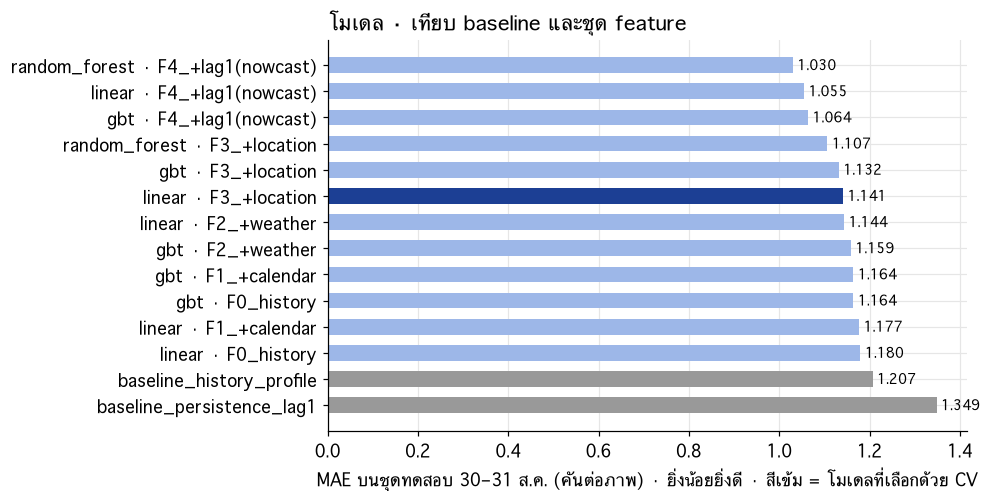

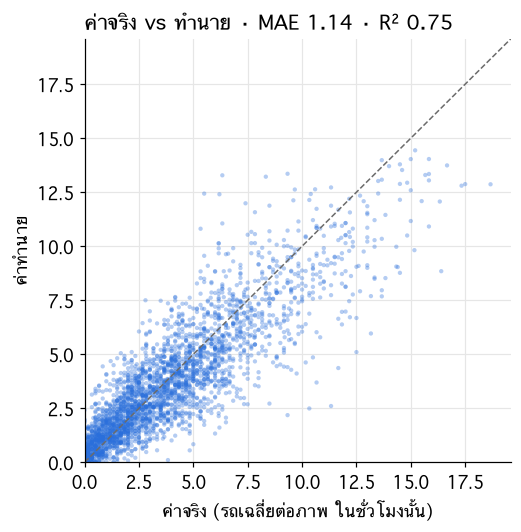

In [4]:
display(Image('reports/figures/ml_model_comparison.png'))
display(Image('reports/figures/ml_actual_vs_pred.png'))

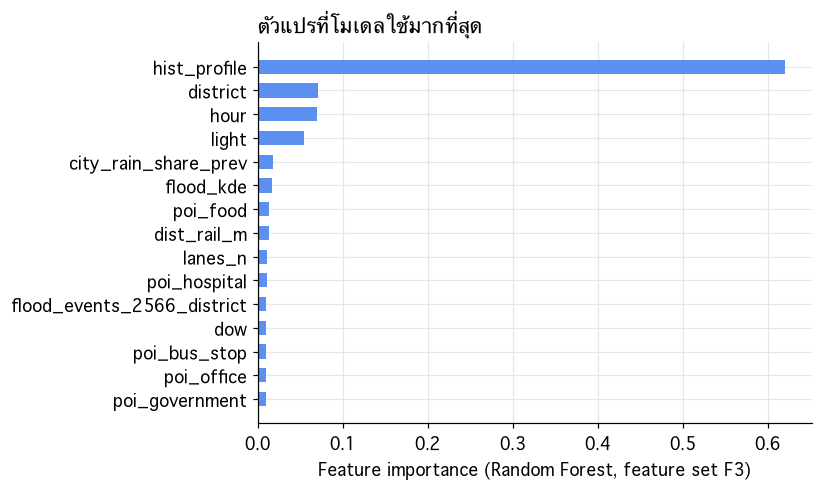

,n,model,baseline
is_weekend=0.0,1496,"{'mae': 1.1016, 'rmse': 1.4912, 'r2': 0.8058}","{'mae': 1.1665, 'rmse': 1.5899, 'r2': 0.7793}"
is_weekend=1.0,1495,"{'mae': 1.1815, 'rmse': 1.6579, 'r2': 0.6536}","{'mae': 1.2474, 'rmse': 1.7645, 'r2': 0.6076}"
rain_prev_level=dry,2646,"{'mae': 1.1363, 'rmse': 1.5642, 'r2': 0.7567}","{'mae': 1.1783, 'rmse': 1.6377, 'r2': 0.7333}"
rain_prev_level=heavy,47,"{'mae': 1.3891, 'rmse': 1.7303, 'r2': 0.5325}","{'mae': 1.7414, 'rmse': 2.3673, 'r2': 0.1249}"
rain_prev_level=light,298,"{'mae': 1.1486, 'rmse': 1.6602, 'r2': 0.6225}","{'mae': 1.3765, 'rmse': 1.9, 'r2': 0.5057}"
light=day,2588,"{'mae': 1.2037, 'rmse': 1.6447, 'r2': 0.7241}","{'mae': 1.2657, 'rmse': 1.7453, 'r2': 0.6893}"
light=night,398,"{'mae': 0.7391, 'rmse': 1.0345, 'r2': 0.4839}","{'mae': 0.8206, 'rmse': 1.1558, 'r2': 0.3557}"


In [5]:
display(Image('reports/figures/ml_feature_importance.png'))
pd.DataFrame(m['best']['by_group']).T

## โมเดลบอกว่าฝนลดรถเท่าไร (counterfactual) และทำนายกล้องที่ไม่เคยเห็น

In [6]:
m['rain_effect'], m['camera_holdout']

({'weekend': {'n': 147,
   'actual': 3.78,
   'pred_with_rain': 3.023,
   'pred_if_dry': 3.455,
   'ratio': 0.875},
  'weekday': {'n': 198,
   'actual': 2.705,
   'pred_with_rain': 3.226,
   'pred_if_dry': 3.693,
   'ratio': 0.873}},
 {'time+weather': {'mae': 2.3241, 'rmse': 3.1286, 'r2': 0.0785},
  'time+weather+location': {'mae': 3.0852, 'rmse': 4.1811, 'r2': -0.7146}})

## โหลด PipelineModel ที่บันทึกไว้แล้วใช้ทำนาย

In [7]:
from pyspark.ml import PipelineModel
from pyspark.sql import functions as F
from src.ml.train_spark import prepare, split, M
df = prepare()
train, test = split(df, M['train_end'], F.col('date') >= str(M['test_start']))
model = PipelineModel.load('models/best_pipeline_model')
(model.transform(test.where("date = '2026-08-31' and hour = 17"))
 .selectExpr('cam', 'rain_prev_level', 'round(veh_mean,2) as actual', 'round(expm1(hist_profile),2) as baseline', 'round(expm1(prediction),2) as predicted')
 .orderBy('cam').show(12))

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/21 22:19:58 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


+----+---------------+------+--------+---------+
| cam|rain_prev_level|actual|baseline|predicted|
+----+---------------+------+--------+---------+
|1028|            dry|   3.0|    4.96|     4.57|
|1039|            dry|  2.17|    3.29|     3.13|
|1060|            dry|   2.5|    0.85|     0.94|
|1063|            dry|  2.17|    3.82|     3.56|
|1070|            dry|  9.17|   10.42|     8.97|
|1071|            dry|   2.5|    3.96|     3.71|
|1076|            dry|   4.5|    7.17|     6.57|
|1078|            dry|  3.67|    7.09|     6.38|
|  11|            dry|  13.0|   11.73|    10.41|
|1103|          heavy|  4.83|    8.61|     7.62|
|1112|            dry| 12.67|   14.66|    12.34|
| 112|            dry| 14.83|   15.49|    12.94|
+----+---------------+------+--------+---------+
only showing top 12 rows


## MLflow

`mlflow ui --backend-store-uri sqlite:///models/mlflow.db` แล้วเปิด http://127.0.0.1:5000 เพื่อดูทุก run